In [1]:
%load_ext autoreload
%autoreload 2

# Device selection

In [2]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"
device = "ibm_aachen"
# device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

/var/folders/bm/v93fcqrd7kq6vwyfqyx20p5w0000gn/T/ipykernel_1982/3737875437.py:12: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)


# Auxiliary lattice plot

72 possible layouts


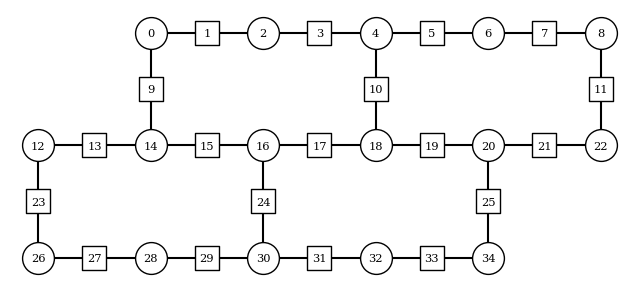

In [3]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 2
plaquette_height = 2

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

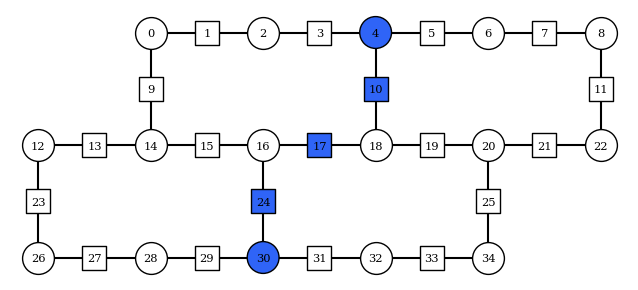

In [4]:
from z2hex.gdd import zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 5
h = 2
lamb = 1

x_basis = False

fractional_gates = False

string = [4, 10, 17, 24, 30]
# string = [27, 26, 34, 43, 52, 60, 59]

final_time = 3
dt = 0.15
steps = 20
desired_error = 1e-2

max_layers = 50
adjust_depth = True

pt_num_randomizations = 8000
pt_shots_per_randomization = 100

# shots = pt_num_randomizations * pt_shots_per_randomization
# max_shots = 10000000
shots = 75000
max_shots = 75000

confidence = 0.9

odr = True
postselect_odr = True
flip_threshold = 1
all_or_first_layout_qubit = None
forbidden_qubits = []
max_layouts = 5
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": shots/500,
        "shots_per_randomization": 500
    }
}
# execution_database = "z2_hex_jobs_dec.json" # Last db with good jobs / Not in the new order
execution_database = "z2_hex_jobs_2tdec.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = "Curated data/"

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string), number_qubits=True, filepath="z2hex_quench_initial_state.png")

# Load hardware jobs

In [5]:
from utils.postselection_multithreaded import load_postselected_jobs_obs
import pickle
import os

curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_dd_{sampler_options["dynamical_decoupling"]["enable"]}_pt_{sampler_options["twirling"]["enable_gates"]}_ft_{flip_threshold}_pODR_{postselect_odr}_confidence_{confidence}.pkl")

with open(curated_data_filepath, "rb") as f:
    hardware_observables, hardware_observables_confidence, samples_dicts, postselected_samples_dicts, layouts = pickle.load(f)

# Load TN data

In [6]:
import numpy as np
import os

tn_dt = 0.01
tn_final_time = 16
tn_exp_order = 30
tn_bond_dimension = 128
tn_data_folderpath = "TN Data/"
tn_data_limit = int(final_time / tn_dt)
tn_data_step = int(dt / tn_dt)

tn_data_filepath = os.path.join(tn_data_folderpath, f"converted_data_BUG_g{h:.02f}_m{J:.02f}_ROWS{plaquette_width}_COLS{plaquette_height}_dt{tn_dt:.03f}_Tmax{tn_final_time:.02f}_exp_order{tn_exp_order}_M{tn_bond_dimension:05d}.txt")
# tn_data_filepath = os.path.join(tn_data_folderpath, f"converted_data_BUG_g{h:.02f}_m{J:.02f}_{plaquette_width}x{plaquette_height}_dt{tn_dt:.03f}_Tmax{tn_final_time:.02f}_exp_order{tn_exp_order}_M{tn_bond_dimension:05d}.txt")
tn_observables = np.loadtxt(tn_data_filepath)

# Single frame

## Hardware

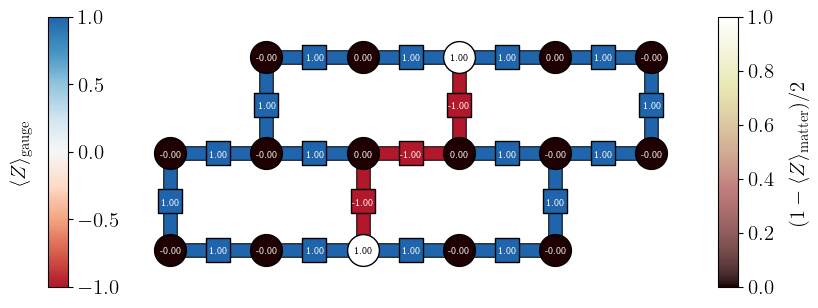

In [7]:
from utils.postselection import initialize_postselection, measure_diagonal_observables, get_recovered_postselected_samples_dict
from z2hex.plotting import local_observable_plot, truncate_colormap
import matplotlib.pyplot as plt
import utils.odr as odr

cmap_matter = truncate_colormap(plt.get_cmap("pink"), 0, 1)
cmap_gauge = truncate_colormap(plt.get_cmap("RdBu"), 0.1, 0.9)

cmap_range_matter = [0, 1]
cmap_range_gauge = [-1, 1]
cmap_label_matter = r"$(1 - \langle Z \rangle_{\mathrm{matter}})/2$"
cmap_label_gauge = r"$\langle Z \rangle_{\mathrm{gauge}}$"

job_index_hardware = 0

matter_qb_inds = lattice.node_qbinds

observables_to_plot = hardware_observables[0][job_index_hardware].copy()
observables_to_plot[matter_qb_inds] = (1 - observables_to_plot[matter_qb_inds])/2
# observables_to_plot = (1 - observables_to_plot)/2

local_observable_plot(observables_to_plot, lattice, cmap_matter=cmap_matter, cmap_gauge=cmap_gauge, cmap_range_gauge=cmap_range_gauge, cmap_range_matter=cmap_range_matter, cmap_label_matter=cmap_label_matter, cmap_label_gauge=cmap_label_gauge, facecolor="white")

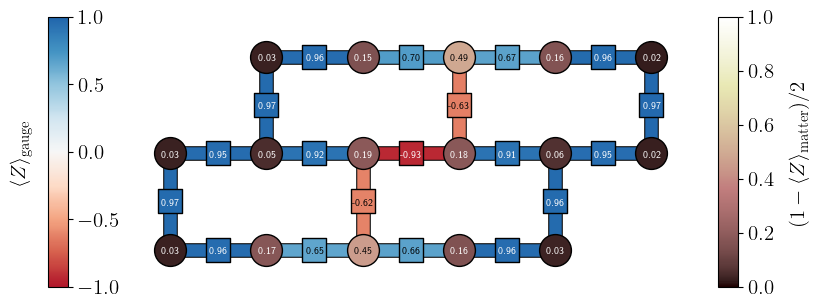

In [8]:
from utils.postselection import initialize_postselection, measure_diagonal_observables, get_recovered_postselected_samples_dict
from z2hex.plotting import local_observable_plot, truncate_colormap
import matplotlib.pyplot as plt
import utils.odr as odr

cmap_matter = truncate_colormap(plt.get_cmap("pink"), 0, 1)
cmap_gauge = truncate_colormap(plt.get_cmap("RdBu"), 0.1, 0.9)
cmap_label_matter = r"$(1 - \langle Z \rangle_{\mathrm{matter}})/2$"
cmap_label_gauge = r"$\langle Z \rangle_{\mathrm{gauge}}$"

cmap_range_matter = [0, 1]
cmap_range_gauge = [-1, 1]

job_index_hardware = 5

matter_qb_inds = lattice.node_qbinds

observables_to_plot = hardware_observables[0][job_index_hardware].copy()
observables_to_plot[matter_qb_inds] = (1 - observables_to_plot[matter_qb_inds])/2
# observables_to_plot = (1 - observables_to_plot)/2

local_observable_plot(observables_to_plot, lattice, cmap_matter=cmap_matter, cmap_gauge=cmap_gauge, cmap_range_gauge=cmap_range_gauge, cmap_range_matter=cmap_range_matter, cmap_label_matter=cmap_label_matter, cmap_label_gauge=cmap_label_gauge, facecolor="white")

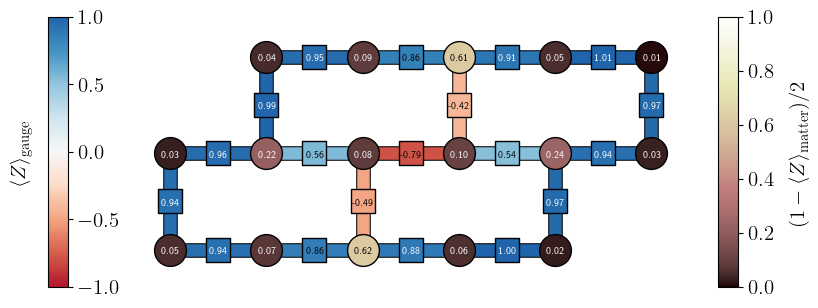

In [9]:
from utils.postselection import initialize_postselection, measure_diagonal_observables, get_recovered_postselected_samples_dict
from z2hex.plotting import local_observable_plot, truncate_colormap
import matplotlib.pyplot as plt
import utils.odr as odr

cmap_matter = truncate_colormap(plt.get_cmap("pink"), 0, 1)
cmap_gauge = truncate_colormap(plt.get_cmap("RdBu"), 0.1, 0.9)

cmap_range_matter = [0, 1]
cmap_range_gauge = [-1, 1]
cmap_label_matter = r"$(1 - \langle Z \rangle_{\mathrm{matter}})/2$"
cmap_label_gauge = r"$\langle Z \rangle_{\mathrm{gauge}}$"

job_index_hardware = 20

matter_qb_inds = lattice.node_qbinds

observables_to_plot = hardware_observables[0][job_index_hardware].copy()
observables_to_plot[matter_qb_inds] = (1 - observables_to_plot[matter_qb_inds])/2

local_observable_plot(observables_to_plot, lattice, cmap_matter=cmap_matter, cmap_gauge=cmap_gauge, cmap_range_gauge=cmap_range_gauge, cmap_range_matter=cmap_range_matter, cmap_label_matter=cmap_label_matter, cmap_label_gauge=cmap_label_gauge, facecolor="white")

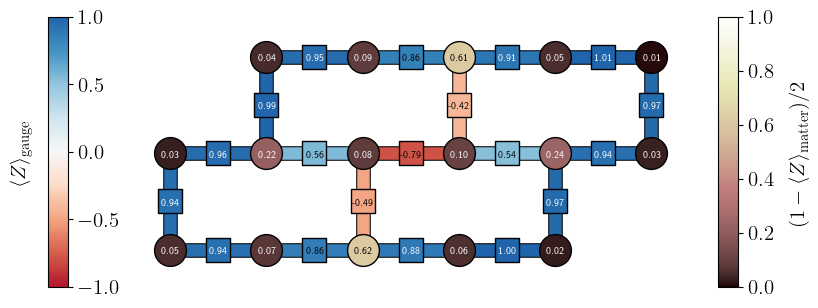

In [10]:
from utils.postselection import initialize_postselection, measure_diagonal_observables, get_recovered_postselected_samples_dict
from z2hex.plotting import local_observable_plot, truncate_colormap
import matplotlib.pyplot as plt
import utils.odr as odr

cmap_matter = truncate_colormap(plt.get_cmap("pink"), 0, 1)
cmap_gauge = truncate_colormap(plt.get_cmap("RdBu"), 0.1, 0.9)

cmap_range_matter = [0, 1]
cmap_range_gauge = [-1, 1]
cmap_label_matter = r"$(1 - \langle Z \rangle_{\mathrm{matter}})/2$"
cmap_label_gauge = r"$\langle Z \rangle_{\mathrm{gauge}}$"

job_index_hardware = 20

matter_qb_inds = lattice.node_qbinds

observables_to_plot = hardware_observables[0][job_index_hardware].copy()
observables_to_plot[matter_qb_inds] = (1 - observables_to_plot[matter_qb_inds])/2
# observables_to_plot = (1 - observables_to_plot)/2

local_observable_plot(observables_to_plot, lattice, cmap_matter=cmap_matter, cmap_gauge=cmap_gauge, cmap_range_gauge=cmap_range_gauge, cmap_range_matter=cmap_range_matter, cmap_label_matter=cmap_label_matter, cmap_label_gauge=cmap_label_gauge, facecolor="white")

## TN

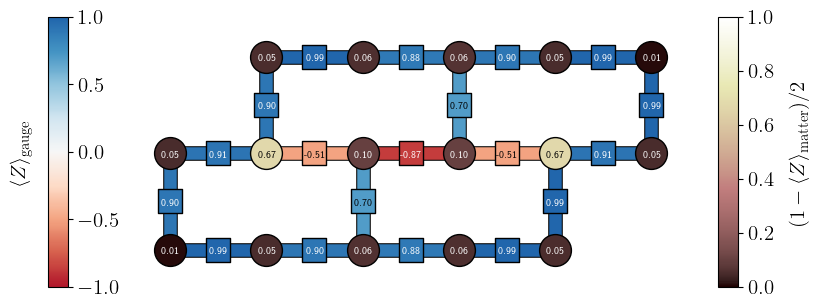

In [11]:
from utils.postselection import initialize_postselection, measure_diagonal_observables, get_recovered_postselected_samples_dict
from z2hex.plotting import local_observable_plot
import matplotlib.pyplot as plt
import utils.odr as odr

cmap_matter = truncate_colormap(plt.get_cmap("pink"), 0, 1)
# cmap_matter = truncate_colormap(plt.get_cmap("inferno"), 0, 1)
cmap_gauge = truncate_colormap(plt.get_cmap("RdBu"), 0.1, 0.9)

cmap_range_matter = [0, 1]
cmap_range_gauge = [-1, 1]
cmap_label_matter = r"$(1 - \langle Z \rangle_{\mathrm{matter}})/2$"
cmap_label_gauge = r"$\langle Z \rangle_{\mathrm{gauge}}$"

job_index_tn = 54*tn_data_step

matter_qb_inds = lattice.node_qbinds

observables_to_plot = tn_observables[job_index_tn, :].copy()
observables_to_plot[matter_qb_inds] = (1 - observables_to_plot[matter_qb_inds])/2

local_observable_plot(observables_to_plot, lattice, cmap_matter=cmap_matter, cmap_gauge=cmap_gauge, cmap_range_gauge=cmap_range_gauge, cmap_range_matter=cmap_range_matter, cmap_label_matter=cmap_label_matter, cmap_label_gauge=cmap_label_gauge, facecolor="white")

## Combined lattice plot

# Contour plots

## Hardware

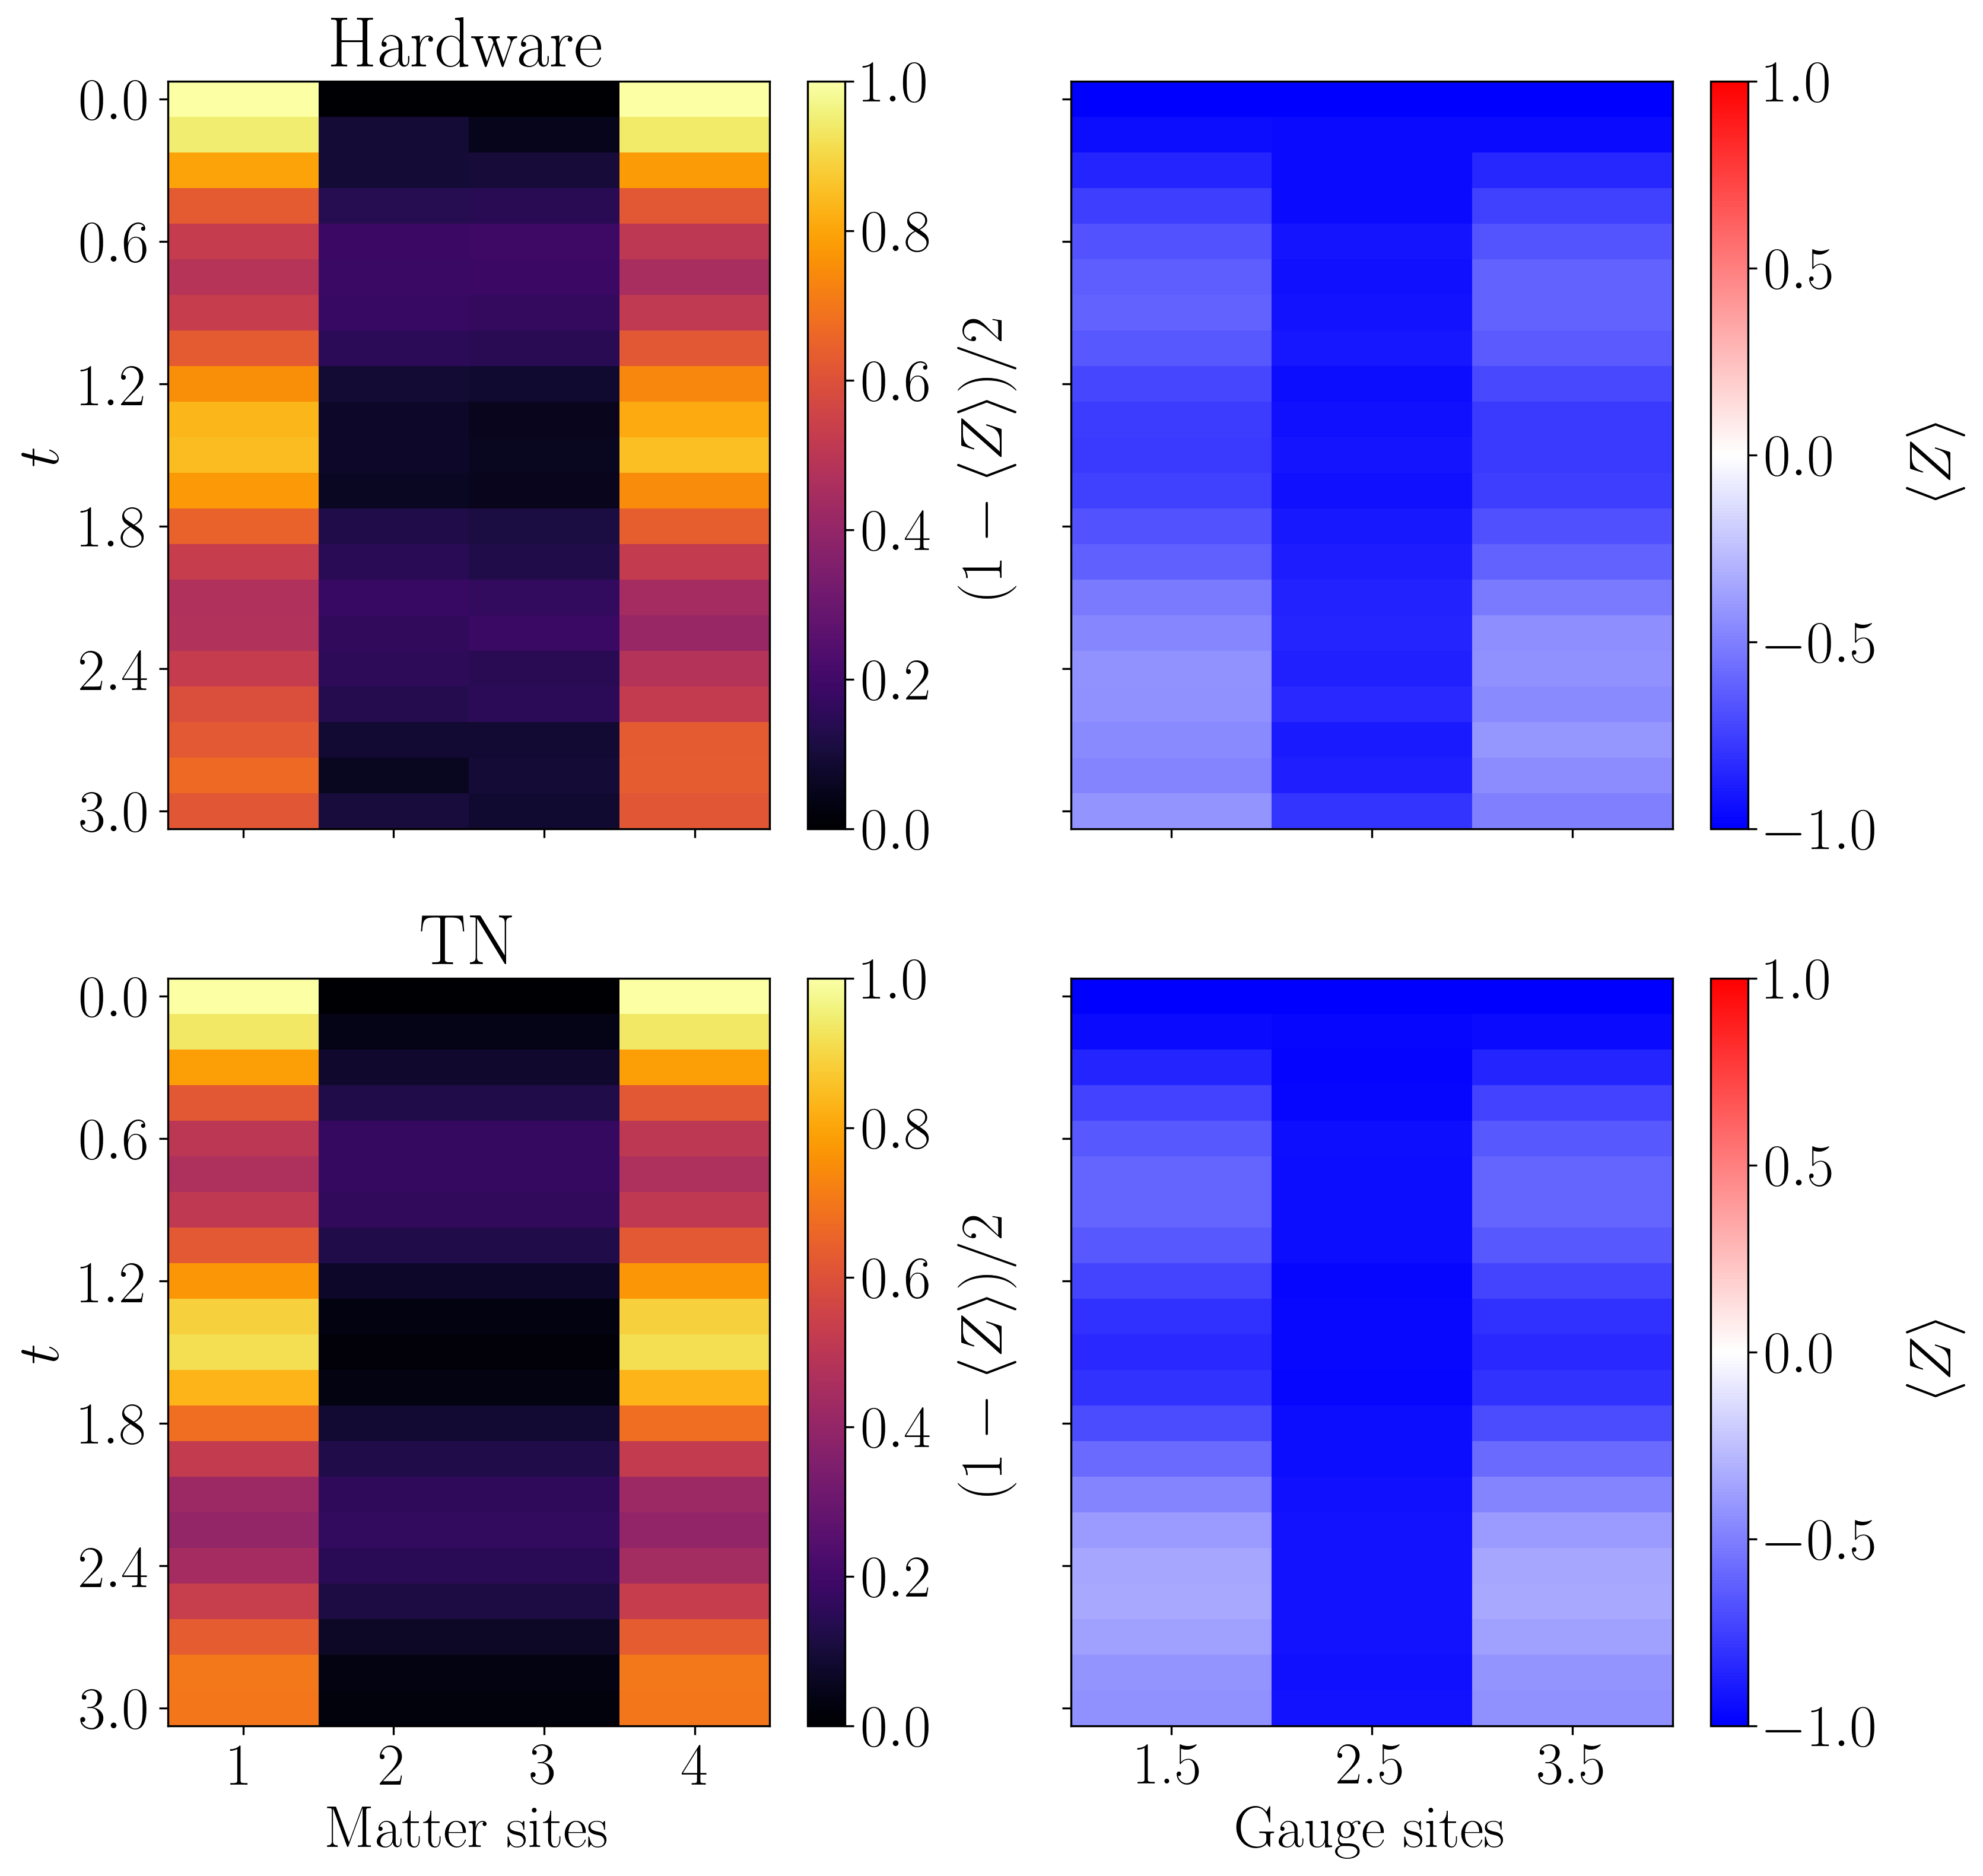

In [12]:
from z2chain.plotting import x_t_separated_plot_htn_comparison

# qubits = [6, 5, 4, 10, 18, 17, 16, 24, 30, 29, 28]
qubits = [4, 10, 18, 17, 16, 24, 30]

y_ticks = (np.linspace(0, final_time, 6))
ylabel = r"$t$"
plot_filepath = f"z2hex_contour_qubits_tnhardwarecomp_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.png"

hardware_observables_to_plot = hardware_observables[0][:, qubits]
tn_observables_to_plot = tn_observables[:tn_data_limit+1:tn_data_step, qubits]

x_t_separated_plot_htn_comparison(hardware_observables_to_plot, tn_observables_to_plot, y_ticks=y_ticks, ylabel=ylabel, filepath=plot_filepath)

## Seeing where the longest point in TN is worth it

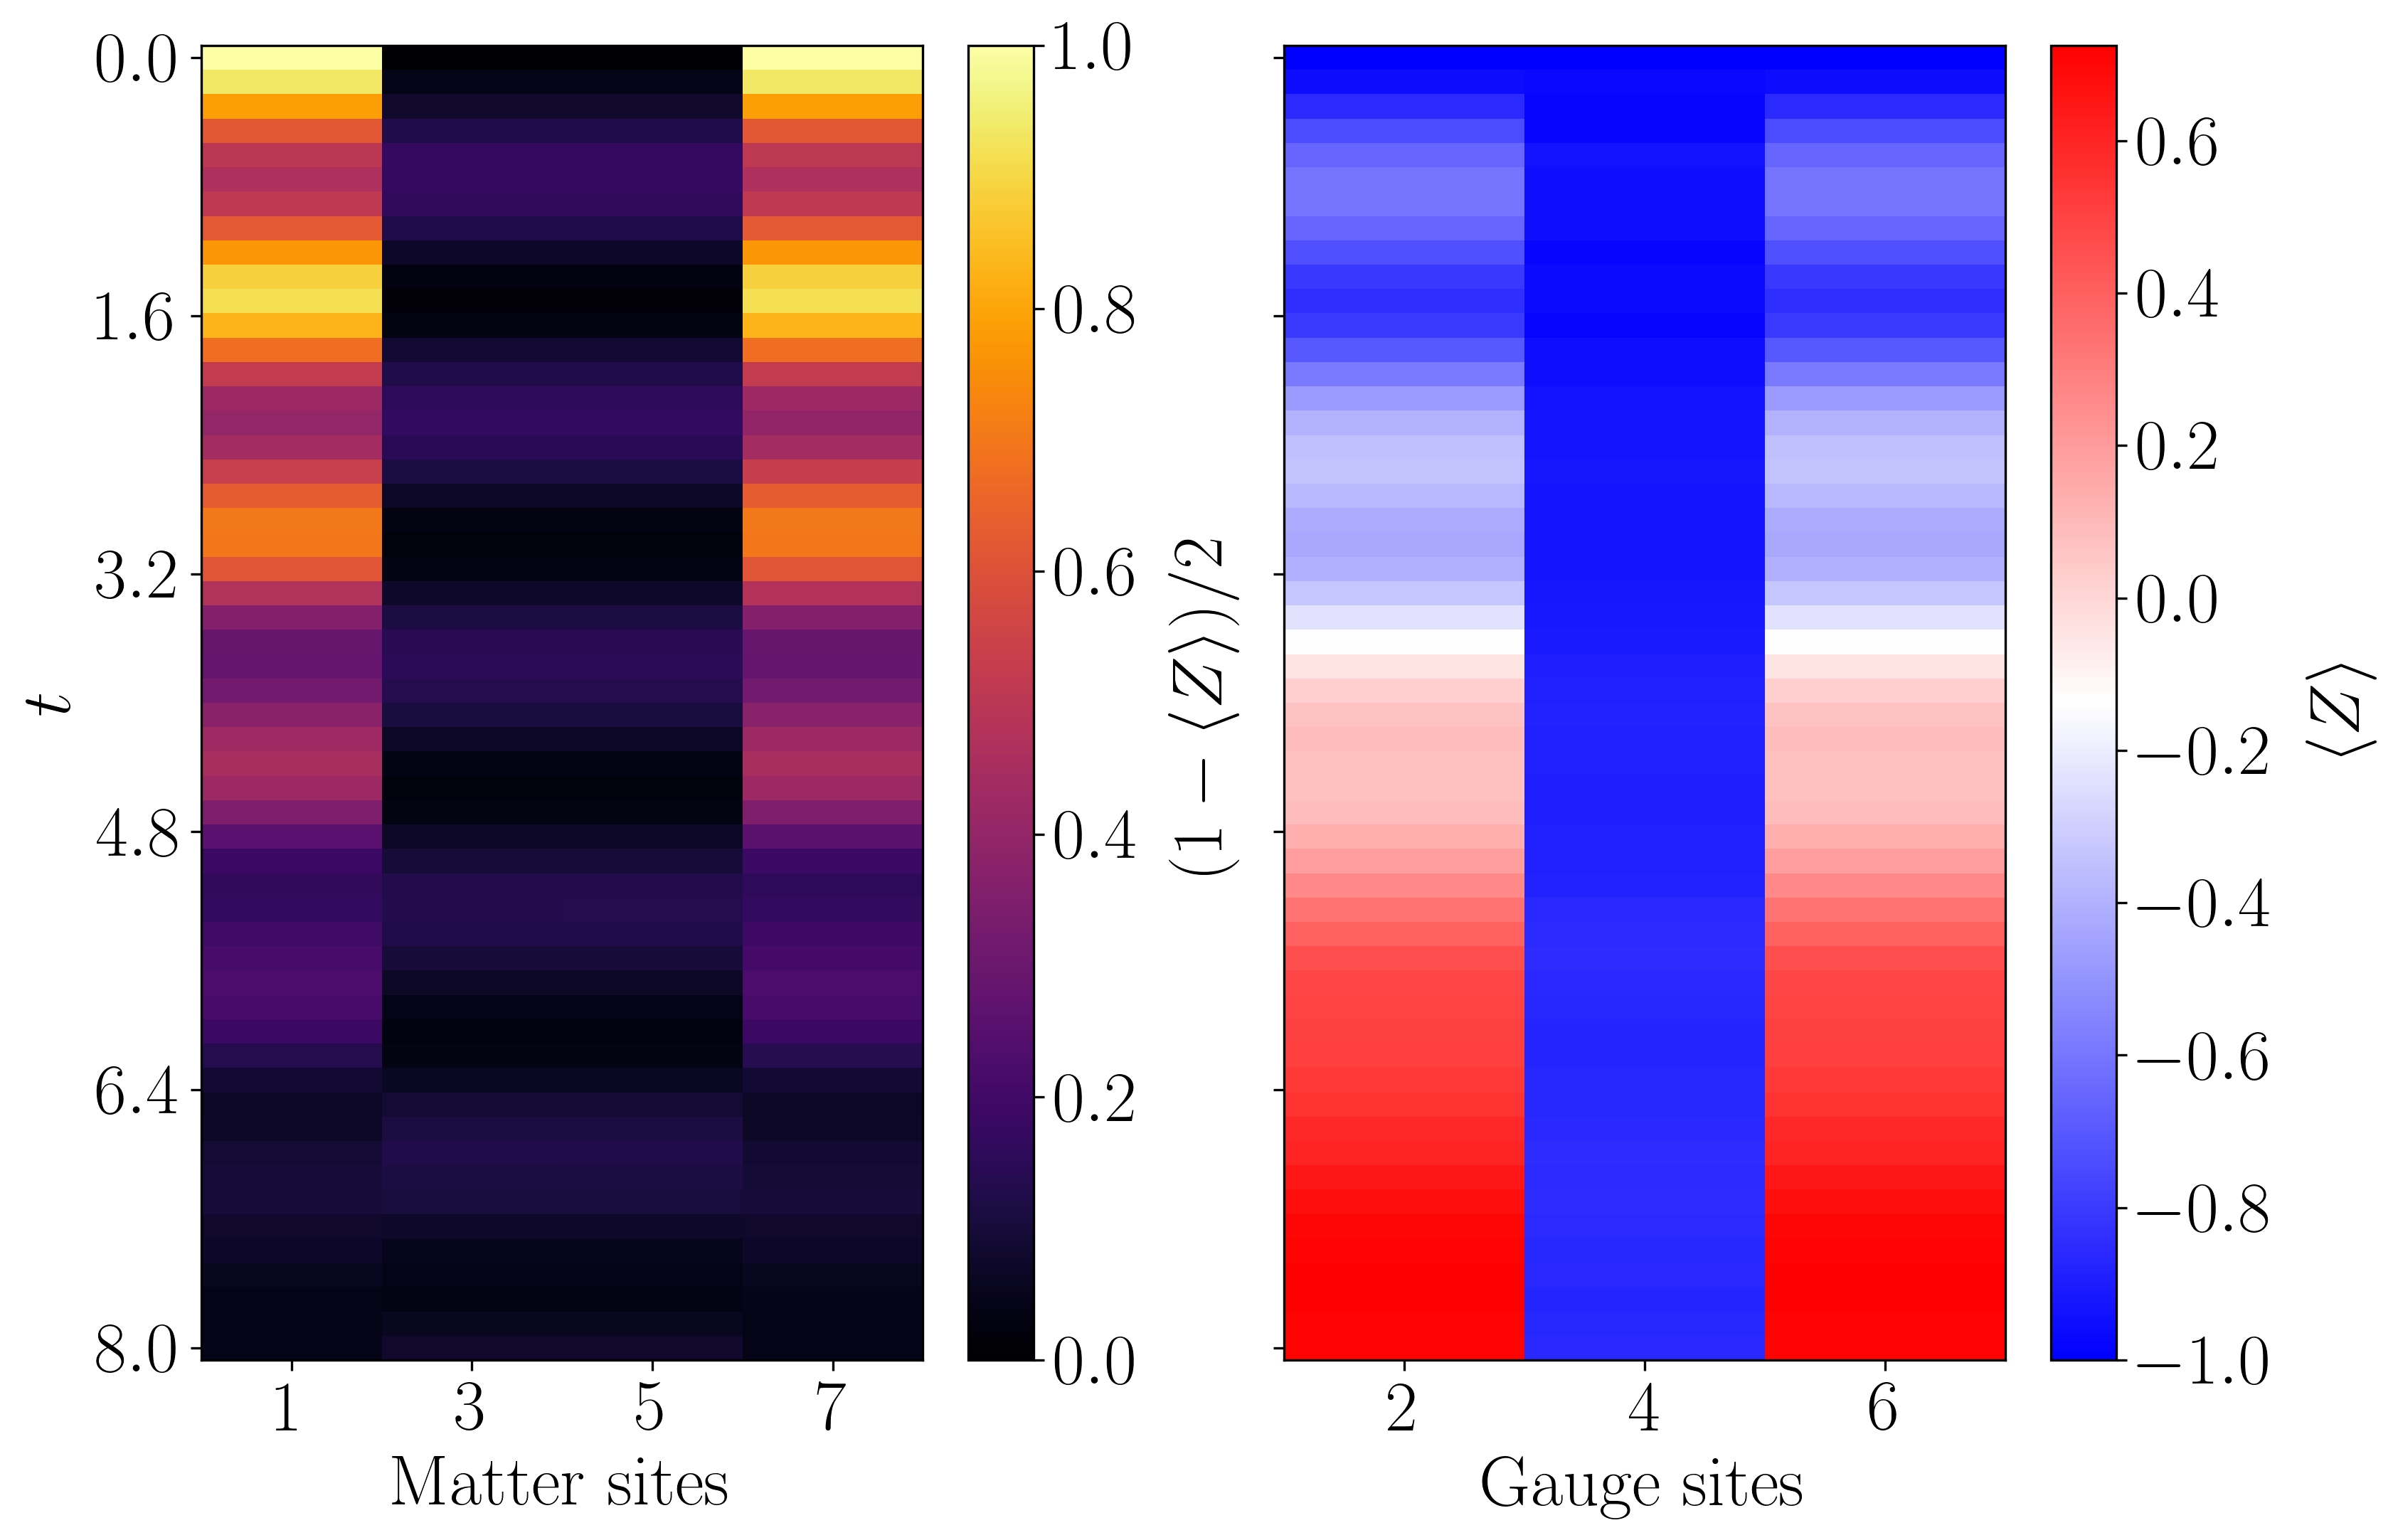

In [13]:
from z2chain.plotting import x_t_separated_plot

qubits = [4, 10, 18, 17, 16, 24, 30]

this_final_time = 8
this_tn_data_limit = int(this_final_time / tn_dt)

y_ticks = (np.linspace(0, this_final_time, 6))
ylabel = r"$t$"
plot_filepath = f"z2hex_contour_qubits_longtn_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.png"

hardware_observables_to_plot = hardware_observables[0][:, qubits]
tn_observables_to_plot = tn_observables[:this_tn_data_limit+1:tn_data_step, qubits]

x_t_separated_plot(tn_observables_to_plot, y_ticks=y_ticks, ylabel=ylabel, filepath=plot_filepath)

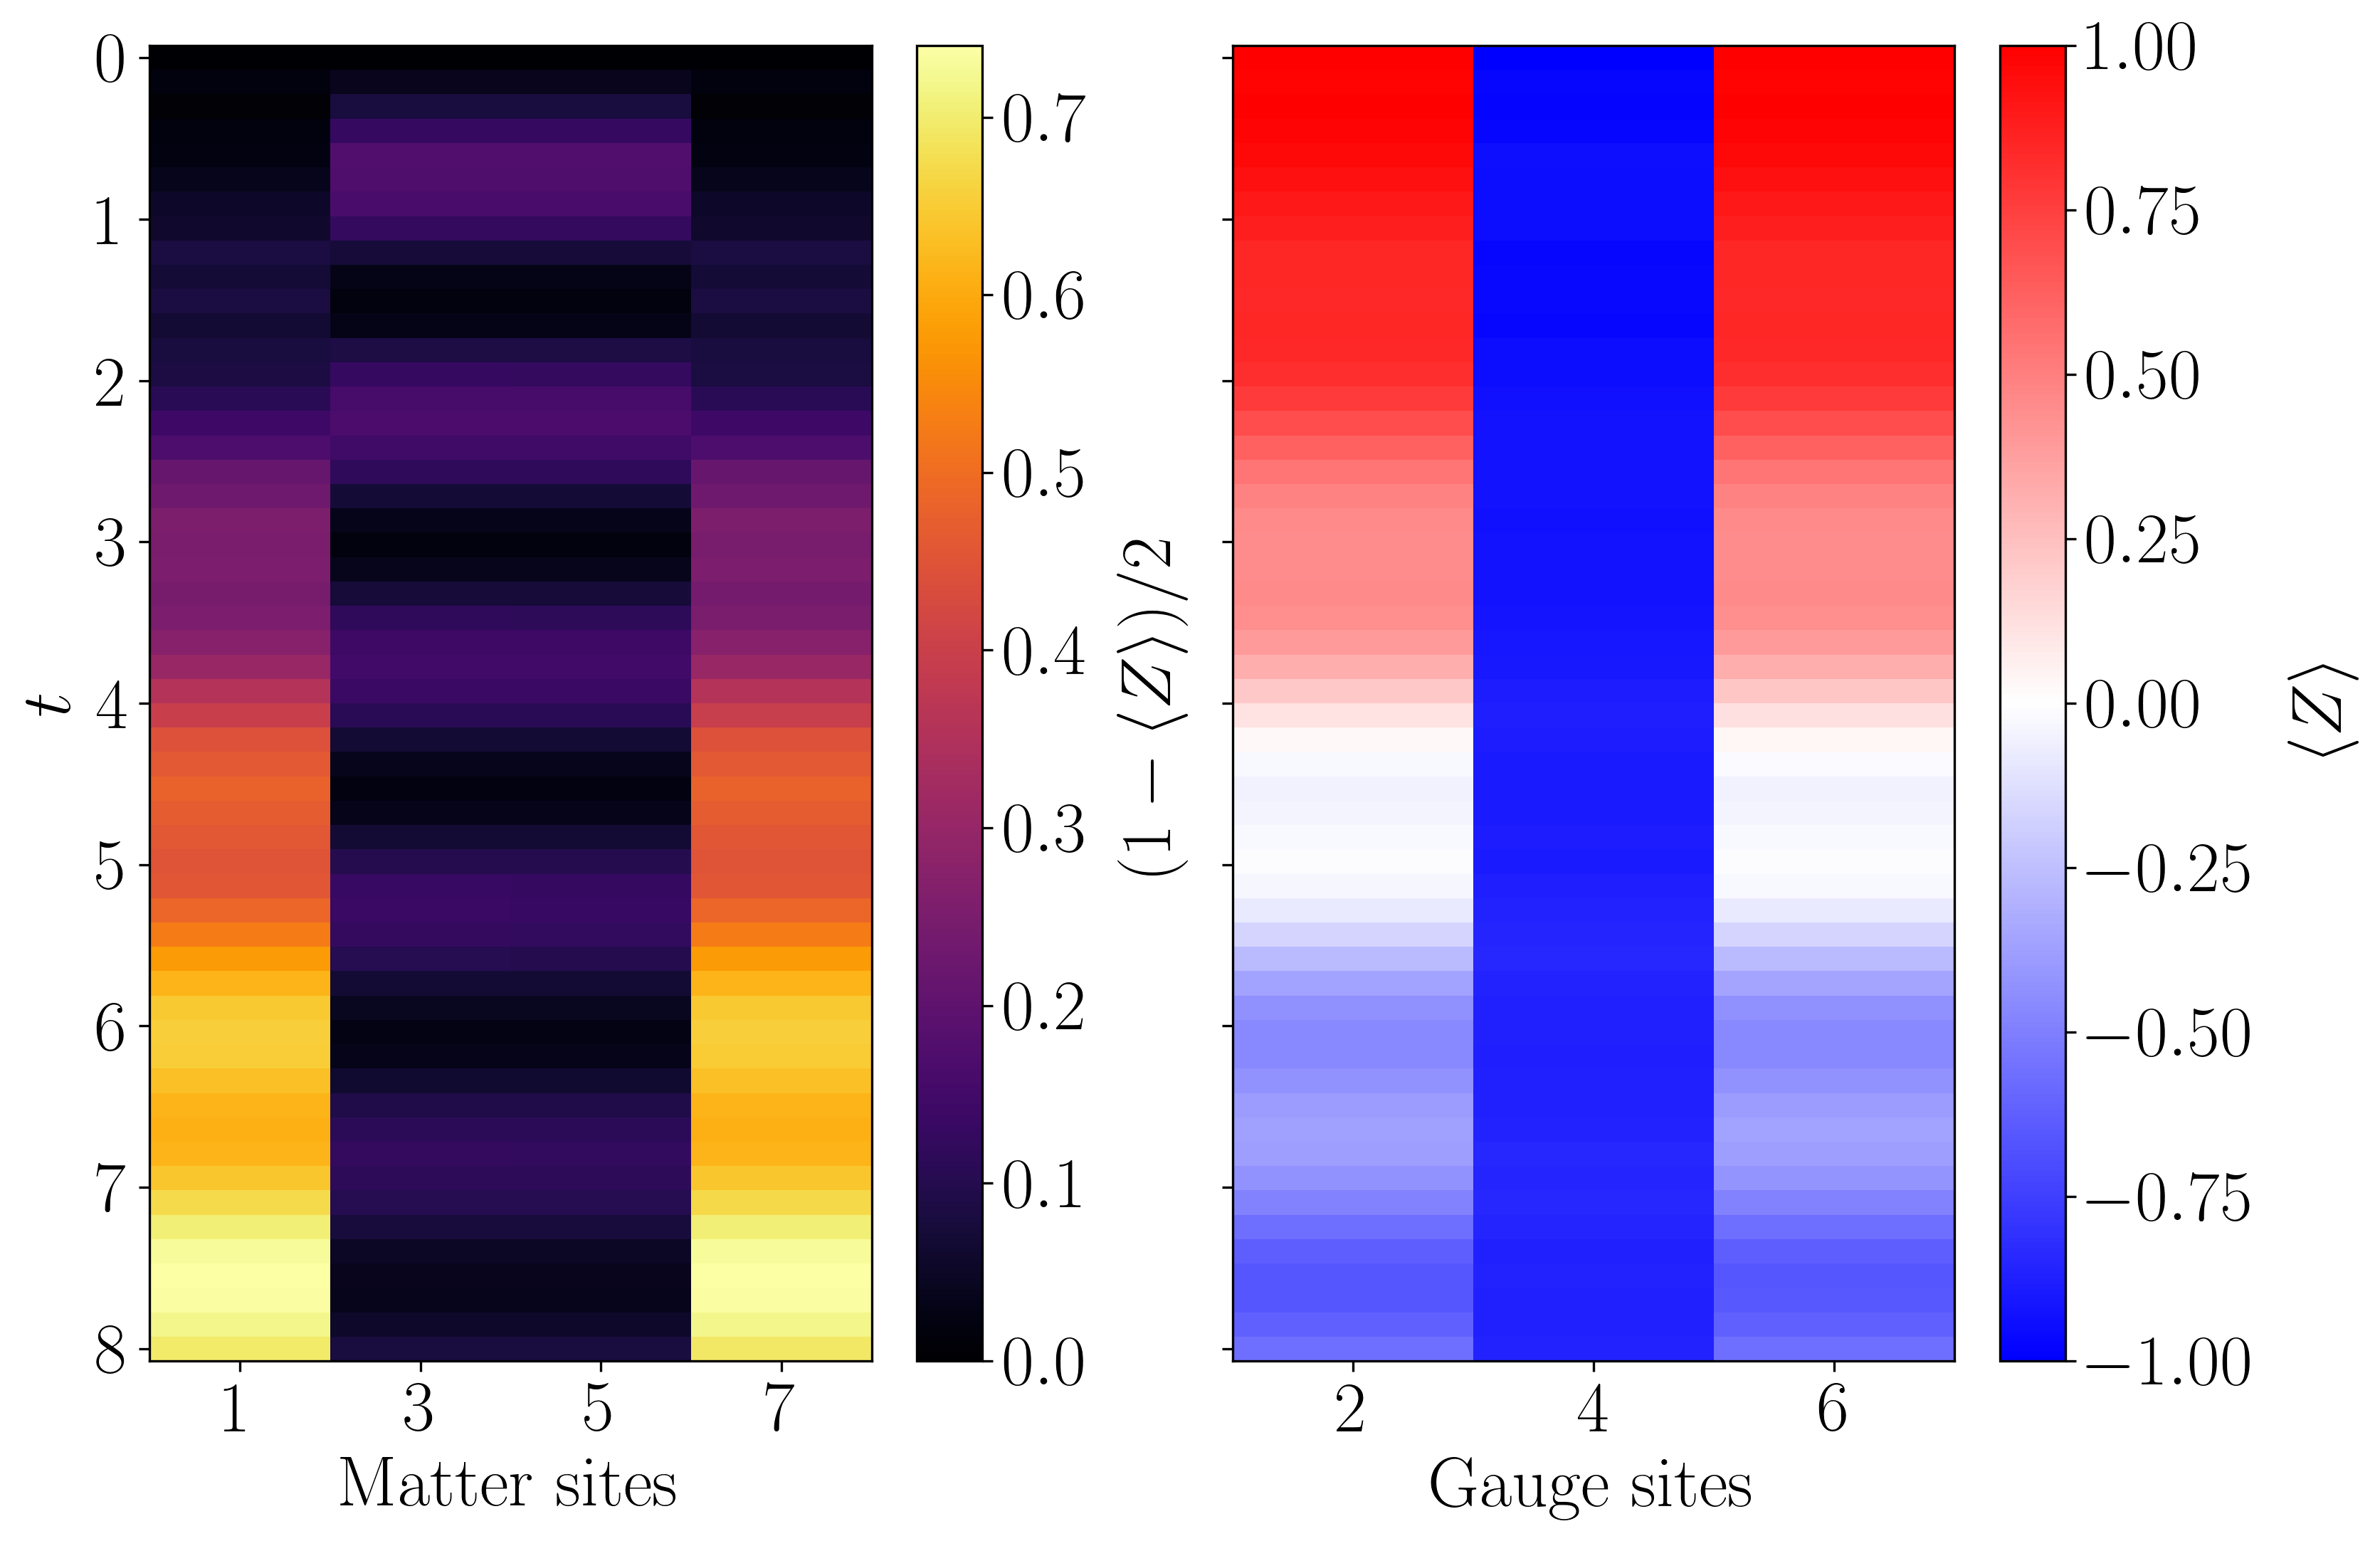

In [14]:
from z2chain.plotting import x_t_separated_plot

qubits = list(range(14, 21))

this_final_time = 8
this_tn_data_limit = int(this_final_time / tn_dt)

y_ticks = (np.linspace(0, this_final_time, 9))
ylabel = r"$t$"
plot_filepath = f"z2hex_contour_qubits_longtn_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.png"

tn_observables_to_plot = tn_observables[:this_tn_data_limit+1:tn_data_step, qubits]

x_t_separated_plot(tn_observables_to_plot, y_ticks=y_ticks, ylabel=ylabel, filepath=plot_filepath)

$t = 8$ is reasonable

## Hardware & TN matter combined plot

In [15]:
hardware_observables[0][0, qubits]

array([ 1.00036006,  0.99997287,  0.99986353, -0.9998904 ,  0.99813014,
        1.00046974,  1.00094079])

Text(0, 0.5, '$(1 - \\langle Z \\rangle)/2$')

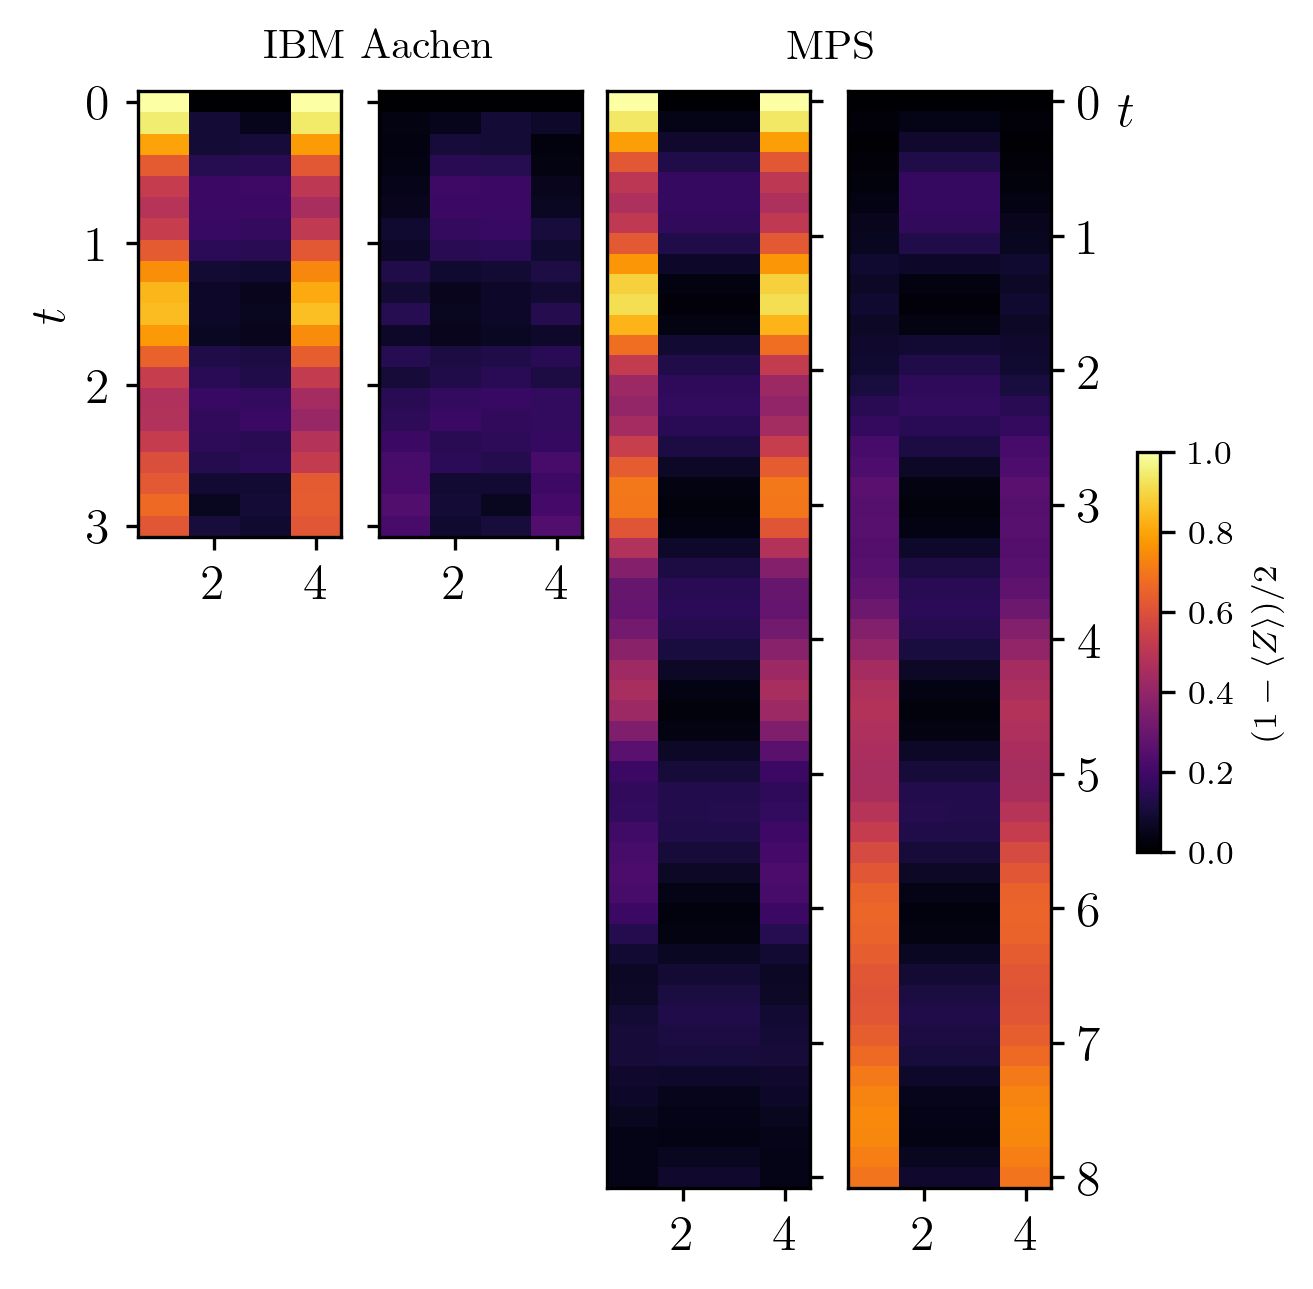

In [114]:
import matplotlib.pyplot as plt
import numpy as np

final_time_tn = 8

qubits_1 = [4, 10, 18, 17, 16, 24, 30][::2]
qubits_2 = list(range(14, 21))[::2]

this_tn_data_limit = int(this_final_time / tn_dt)
ticklabels_tn = np.linspace(0, final_time_tn, int(np.ceil(final_time_tn))+1)

hardware_observables_to_plot = hardware_observables[0]
tn_observables_to_plot = tn_observables[:this_tn_data_limit+1:tn_data_step, :]

cmap = plt.get_cmap("inferno")
cmap_interval = [0, 1]
cbar_label = r"$(1 - \langle Z \rangle)/2$"

scalar_mappable = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=cmap_interval[0], vmax=cmap_interval[1]))

y_ticks = (np.linspace(0, final_time_tn, 9))

plt.rc("text", usetex=True)
plt.rc("font", size=12, family="serif", weight="bold")

x1 = np.arange(1, len(qubits_1)+1)
x2 = np.arange(1, len(qubits_2)+1)
yh = np.linspace(0, final_time, hardware_observables_to_plot.shape[0])
ytn = np.linspace(0, final_time_tn, tn_observables_to_plot.shape[0])
Xh1, Yh1 = np.meshgrid(x1, yh)
Xh2, Yh2 = np.meshgrid(x2, yh)
Xtn1, Ytn1 = np.meshgrid(x1, ytn)
Xtn2, Ytn2 = np.meshgrid(x2, ytn)
Zh1 = (1 - hardware_observables_to_plot[:, qubits_1])/2
Zh2 = (1 - hardware_observables_to_plot[:, qubits_2])/2
Ztn1 = (1 - tn_observables_to_plot[:, qubits_1])/2
Ztn2 = (1 - tn_observables_to_plot[:, qubits_2])/2

fig = plt.figure(figsize=[3.77, 4], dpi=300, layout="constrained")
axs = fig.subplot_mosaic(
    """
    ABCD
    ..CD
    ..CD
    """,
    height_ratios=[final_time/final_time_tn, (final_time/final_time_tn)/2, (final_time/final_time_tn)/2],
)

axs["A"].pcolormesh(Xh1, Yh1, Zh1, cmap=cmap, shading="auto", vmin=cmap_interval[0], vmax=cmap_interval[1])
axs["B"].pcolormesh(Xh2, Yh2, Zh2, cmap=cmap, shading="auto", vmin=cmap_interval[0], vmax=cmap_interval[1])
axs["C"].pcolormesh(Xtn1, Ytn1, Ztn1, cmap=cmap, shading="auto", vmin=cmap_interval[0], vmax=cmap_interval[1])
axs["D"].pcolormesh(Xtn2, Ytn2, Ztn2, cmap=cmap, shading="auto", vmin=cmap_interval[0], vmax=cmap_interval[1])

axs["A"].invert_yaxis()
axs["B"].invert_yaxis()
axs["C"].invert_yaxis()
axs["D"].invert_yaxis()

# axs["A"].set_title("IBM Aachen", fontdict={"size": 10})
# axs["B"].set_title("IBM Aachen", fontdict={"size": 10})
# axs["C"].set_title("MPS", fontdict={"size": 10})
# axs["D"].set_title("MPS", fontdict={"size": 10})

fig.text(0.32, 1.02, "IBM Aachen", ha="center", va="center", fontdict={"size": 10})
fig.text(0.72, 1.02, "MPS", ha="center", va="center", fontdict={"size": 10})

ticklabels_hardware = []
for lb in ticklabels_tn:
    if yh[0] <= lb <= yh[-1]:
        ticklabels_hardware.append(lb)

axs["A"].set_yticks(ticklabels_hardware)
axs["A"].tick_params(axis="both", width=0.8, length=3)
axs["B"].set_yticks(ticklabels_hardware, [])
axs["B"].tick_params(axis="both", width=0.8, length=3)
axs["C"].set_yticks(ticklabels_tn, [])
axs["C"].tick_params(axis="both", width=0.8, length=3)
axs["D"].set_yticks(ticklabels_tn)
axs["D"].tick_params(axis="both", width=0.8, length=3)
axs["C"].yaxis.tick_right()
axs["D"].yaxis.tick_right()
axs["D"].yaxis.set_label_position("right")

axs["A"].set_ylabel(r"$t$", labelpad=3)
axs["D"].set_ylabel(r"$t$", labelpad=8, loc="top", rotation=0)

cbar_ax = fig.add_axes([0.99, 0.35, 0.02, 1/3])
plt.colorbar(scalar_mappable, cax=cbar_ax)
cbar_ax.tick_params(labelsize=8)
cbar_ax.set_ylabel(cbar_label, labelpad=4, fontdict={"size": 8})
# cbar_ax.text(0.2, 1, r"$(1-\langle Z \rangle)/2$", fontdict={"size": 8}, ha="center", va="center")

# plt.tight_layout()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

final_time_tn = 8

qubits_1 = [4, 10, 18, 17, 16, 24, 30][::2]
qubits_2 = list(range(14, 21))[::2]

this_tn_data_limit = int(this_final_time / tn_dt)
ticklabels_tn = np.linspace(0, final_time_tn, int(np.ceil(final_time_tn))+1)

hardware_observables_to_plot = hardware_observables[0]
tn_observables_to_plot = tn_observables[:this_tn_data_limit+1:tn_data_step, :]

cmap = plt.get_cmap("inferno")
cmap_interval = [0, 1]
cbar_label = r"$(1 - \langle Z \rangle_{\mathrm{matter}})/2$"

scalar_mappable = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=cmap_interval[0], vmax=cmap_interval[1]))

y_ticks = (np.linspace(0, final_time_tn, 9))

plt.rc("text", usetex=True)
plt.rc("font", size=12, family="serif", weight="bold")

x1 = np.arange(1, len(qubits_1)+1)
x2 = np.arange(1, len(qubits_2)+1)
yh = np.linspace(0, final_time, hardware_observables_to_plot.shape[0])
ytn = np.linspace(0, final_time_tn, tn_observables_to_plot.shape[0])
Xh1, Yh1 = np.meshgrid(x1, yh)
Xh2, Yh2 = np.meshgrid(x2, yh)
Xtn1, Ytn1 = np.meshgrid(x1, ytn)
Xtn2, Ytn2 = np.meshgrid(x2, ytn)
Zh1 = (1 - hardware_observables_to_plot[:, qubits_1])/2
Zh2 = (1 - hardware_observables_to_plot[:, qubits_2])/2
Ztn1 = (1 - tn_observables_to_plot[:, qubits_1])/2
Ztn2 = (1 - tn_observables_to_plot[:, qubits_2])/2

fig = plt.figure(figsize=[3.77, 4], dpi=300, layout="constrained")
axs = fig.subplot_mosaic(
    """
    ABCD
    ..CD
    ..CD
    """,
    height_ratios=[final_time/final_time_tn, (final_time/final_time_tn)/2, (final_time/final_time_tn)/2],
)

axs["A"].pcolormesh(Xh1, Yh1, Zh1, cmap=cmap, shading="auto", vmin=cmap_interval[0], vmax=cmap_interval[1])
axs["B"].pcolormesh(Xh2, Yh2, Zh2, cmap=cmap, shading="auto", vmin=cmap_interval[0], vmax=cmap_interval[1])
axs["C"].pcolormesh(Xtn1, Ytn1, Ztn1, cmap=cmap, shading="auto", vmin=cmap_interval[0], vmax=cmap_interval[1])
axs["D"].pcolormesh(Xtn2, Ytn2, Ztn2, cmap=cmap, shading="auto", vmin=cmap_interval[0], vmax=cmap_interval[1])

axs["A"].invert_yaxis()
axs["B"].invert_yaxis()
axs["C"].invert_yaxis()
axs["D"].invert_yaxis()

axs["A"].set_title("IBM Aachen", fontdict={"size": 10})
axs["B"].set_title("IBM Aachen", fontdict={"size": 10})
axs["C"].set_title("MPS", fontdict={"size": 10})
axs["D"].set_title("MPS", fontdict={"size": 10})

ticklabels_hardware = []
for lb in ticklabels_tn:
    if yh[0] <= lb <= yh[-1]:
        ticklabels_hardware.append(lb)

axs["A"].set_yticks(ticklabels_hardware)
axs["A"].tick_params(axis="both", width=0.8, length=3)
axs["B"].set_yticks(ticklabels_hardware, [])
axs["B"].tick_params(axis="both", width=0.8, length=3)
axs["C"].set_yticks(ticklabels_tn, [])
axs["C"].tick_params(axis="both", width=0.8, length=3)
axs["D"].set_yticks(ticklabels_tn)
axs["D"].tick_params(axis="both", width=0.8, length=3)
axs["C"].yaxis.tick_right()
axs["D"].yaxis.tick_right()
axs["D"].yaxis.set_label_position("right")

axs["A"].set_ylabel(r"$t$", labelpad=10)
axs["D"].set_ylabel(r"$t$", labelpad=10, loc="top")

cbar_ax = fig.add_axes([0.98, 0.175, 0.02, 2/3])
plt.colorbar(scalar_mappable, cax=cbar_ax)
cbar_ax.set_ylabel(cbar_label, labelpad=8, fontdict={"size": 8})

# plt.tight_layout()

In [17]:
x1

array([1, 2, 3, 4])